
# MarketPulse AI: Trading Strategy Backtest

## Stock Markets Analytics Zoomcamp 2026
### Capstone Project

### Objectives

1. Load the trained Random Forest classifier and locked trading configuration.
2. Load historical stock prices and saved test predictions.
3. Generate trading signals using the locked 0.60 probability threshold.
4. Execute trades no earlier than the next trading session.
5. Simulate a 10-trading-day holding period.
6. Account for transaction costs and slippage.
7. Construct a portfolio with defined capital and position-sizing rules.
8. Compare portfolio performance against SPY.
9. Calculate cumulative returns, Sharpe ratio, volatility, and maximum drawdown.
10. Document strategy limitations and out-of-sample results.

### Locked Strategy

- Model: Random Forest Classifier
- Features: 24 market-derived indicators
- Signal threshold: 0.60
- Prediction horizon: 10 trading days
- Signal generation: After market close
- Trade execution: Next trading session
- Model selection: Completed using validation data
- Test period: July 16, 2025 – October 21, 2026

### Backtesting Principles

- Do not retrain or retune the model using test results.
- Do not execute trades using unavailable future prices.
- Avoid overlapping or duplicate positions beyond portfolio limits.
- Include realistic transaction costs and slippage.
- Use consistent execution assumptions for the strategy and benchmark.
- Distinguish model prediction accuracy from realized portfolio returns.


In [1]:

# Cell 1 - Load Model, Configuration, Predictions, and Prices

from pathlib import Path
import pandas as pd
import numpy as np
import json
import joblib

# Locate project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

print("Project root:", project_root)

# File paths
model_path = project_root / "models" / "marketpulse_rf_market_only.joblib"
config_path = project_root / "models" / "marketpulse_trading_config.json"
predictions_path = project_root / "results" / "marketpulse_test_predictions.parquet"
prices_path = project_root / "data" / "marketpulse_merged.parquet"

# Verify files exist
for path in [model_path, config_path, predictions_path, prices_path]:
    assert path.exists(), f"Missing file: {path}"

# Load saved artifacts
model = joblib.load(model_path)

with open(config_path, "r", encoding="utf-8") as f:
    trading_config = json.load(f)

test_predictions = pd.read_parquet(predictions_path)
price_df = pd.read_parquet(prices_path)

print("\nMARKETPULSE AI - BACKTEST DATA LOADED")
print("-" * 50)

print("Model:", type(model).__name__)
print("Signal threshold:", trading_config["signal_threshold"])
print("Feature count:", trading_config["feature_count"])

print("\nTest predictions:", test_predictions.shape)
print("Historical prices:", price_df.shape)

print("\nPrice columns:")
print(price_df.columns.tolist())

print("\nPrediction columns:")
print(test_predictions.columns.tolist())

print("\nMissing values in predictions:")
print(test_predictions.isna().sum())

print("\nCell 2 completed successfully.")


Project root: C:\Users\roban\marketpulse-ai

MARKETPULSE AI - BACKTEST DATA LOADED
--------------------------------------------------
Model: RandomForestClassifier
Signal threshold: 0.6
Feature count: 24

Test predictions: (6400, 6)
Historical prices: (46221, 14)

Price columns:
['date', 'ticker', 'open', 'high', 'low', 'close', 'volume', 'treasury_10y', 'treasury_2y', 'fed_funds_rate', 'cpi', 'unemployment_rate', 'fear_greed_index', 'value_classification']

Prediction columns:
['date', 'ticker', 'target_return_10d', 'target_direction_10d', 'predicted_probability', 'signal']

Missing values in predictions:
date                     0
ticker                   0
target_return_10d        0
target_direction_10d     0
predicted_probability    0
signal                   0
dtype: int64

Cell 2 completed successfully.


In [2]:

# Cell 2 - Prepare Historical Prices and Trading Signals

# Create working copies
prices = price_df.copy()
signals = test_predictions.copy()

# Standardize dates
prices["date"] = pd.to_datetime(prices["date"])
signals["date"] = pd.to_datetime(signals["date"])

# Standardize ticker symbols
prices["ticker"] = prices["ticker"].astype(str).str.upper()
signals["ticker"] = signals["ticker"].astype(str).str.upper()

# Sort historical prices
prices = prices.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

# Check duplicate records
price_duplicates = prices.duplicated(
    ["ticker", "date"]
).sum()

signal_duplicates = signals.duplicated(
    ["ticker", "date"]
).sum()

assert price_duplicates == 0, "Duplicate price records found"
assert signal_duplicates == 0, "Duplicate signal records found"

# Calculate next available trading session
prices["next_open"] = (
    prices.groupby("ticker")["open"].shift(-1)
)

prices["next_date"] = (
    prices.groupby("ticker")["date"].shift(-1)
)

# Match predictions to historical prices
backtest_data = signals.merge(
    prices[
        ["date", "ticker", "close", "next_date", "next_open"]
    ],
    on=["date", "ticker"],
    how="left",
    validate="one_to_one"
)

# Verify signal matching
missing_close = backtest_data["close"].isna().sum()
missing_next_open = backtest_data["next_open"].isna().sum()

print("MARKETPULSE AI - BACKTEST DATA PREPARATION")
print("-" * 50)

print("\nHistorical price records:", len(prices))
print("Test prediction records:", len(signals))
print("Merged backtest records:", len(backtest_data))

print("\nDuplicate price records:", price_duplicates)
print("Duplicate signal records:", signal_duplicates)

print("\nMissing signal-day closing prices:", missing_close)
print("Missing next-session opening prices:", missing_next_open)

print("\nSignal date range:")
print("Start:", backtest_data["date"].min())
print("End:  ", backtest_data["date"].max())

print("\nSAMPLE MATCHED RECORDS")
display(
    backtest_data[
        [
            "date",
            "ticker",
            "predicted_probability",
            "signal",
            "close",
            "next_date",
            "next_open"
        ]
    ].head(10)
)

assert len(backtest_data) == len(signals)
assert missing_close == 0
assert missing_next_open == 0
assert (backtest_data["next_date"] > backtest_data["date"]).all()

print("\nCell 3 verification: PASSED")


MARKETPULSE AI - BACKTEST DATA PREPARATION
--------------------------------------------------

Historical price records: 46221
Test prediction records: 6400
Merged backtest records: 6400

Duplicate price records: 0
Duplicate signal records: 0

Missing signal-day closing prices: 0
Missing next-session opening prices: 0

Signal date range:
Start: 2025-07-16 00:00:00
End:   2026-10-21 00:00:00

SAMPLE MATCHED RECORDS


,date,ticker,predicted_probability,signal,close,next_date,next_open
0,2025-07-16,AAPL,0.541057,0,209.149170,2025-07-17,209.557200
1,2025-07-16,AMZN,0.630319,1,223.190002,2025-07-17,223.320007
2,2025-07-16,BAC,0.521926,0,44.820004,2025-07-17,44.440260
3,2025-07-16,CAT,0.509613,0,406.735718,2025-07-17,408.686259
4,2025-07-16,COST,0.660509,1,943.148804,2025-07-17,942.147559
5,2025-07-16,CVX,0.518482,0,142.648422,2025-07-17,141.925289
6,2025-07-16,GE,0.552309,0,264.432953,2025-07-17,268.029160
7,2025-07-16,GOOGL,0.592735,0,182.332321,2025-07-17,181.505202
8,2025-07-16,GS,0.571273,0,691.446228,2025-07-17,688.968463
9,2025-07-16,HD,0.535059,0,345.596954,2025-07-17,344.765332



Cell 3 verification: PASSED


In [3]:

# Cell 3 - Calculate Trade Entry and Exit Prices

holding_period = trading_config["prediction_horizon_days"]

# Calculate exit prices 10 trading sessions after entry
# Entry: t+1 open
# Exit:  t+11 open

prices["exit_date"] = (
    prices.groupby("ticker")["date"].shift(-(holding_period + 1))
)

prices["exit_open"] = (
    prices.groupby("ticker")["open"].shift(-(holding_period + 1))
)

# Merge exit information
backtest_data = backtest_data.merge(
    prices[
        ["date", "ticker", "exit_date", "exit_open"]
    ],
    on=["date", "ticker"],
    how="left",
    validate="one_to_one"
)

# Calculate gross trade returns
backtest_data["gross_return"] = (
    backtest_data["exit_open"] / backtest_data["next_open"] - 1
)

# Identify trades with complete entry and exit data
backtest_data["valid_trade"] = (
    backtest_data["next_open"].notna()
    & backtest_data["exit_open"].notna()
    & (backtest_data["next_open"] > 0)
    & (backtest_data["exit_open"] > 0)
    & (backtest_data["exit_date"] > backtest_data["next_date"])
)

# Extract selected trades
selected_trades = backtest_data[
    (backtest_data["signal"] == 1)
    & (backtest_data["valid_trade"])
].copy()

print("MARKETPULSE AI - TRADE ENTRY AND EXIT PRICES")
print("-" * 50)

print("\nHolding period:", holding_period, "trading sessions")

print("Total test observations:", len(backtest_data))
print("Trading signals:", int(backtest_data["signal"].sum()))
print("Valid selected trades:", len(selected_trades))

print("\nMissing exit prices:",
      backtest_data["exit_open"].isna().sum())

print("\nSAMPLE TRADES")

display(
    selected_trades[
        [
            "date",
            "ticker",
            "next_date",
            "next_open",
            "exit_date",
            "exit_open",
            "gross_return"
        ]
    ].head(10)
)

print("\nGROSS RETURN SUMMARY")
display(
    selected_trades["gross_return"].describe().round(4)
)

assert selected_trades["valid_trade"].all()
assert (
    selected_trades["exit_date"]
    > selected_trades["next_date"]
).all()

print("\nCell 4 verification: PASSED")


MARKETPULSE AI - TRADE ENTRY AND EXIT PRICES
--------------------------------------------------

Holding period: 10 trading sessions
Total test observations: 6400
Trading signals: 2088
Valid selected trades: 2078

Missing exit prices: 20

SAMPLE TRADES


,date,ticker,next_date,next_open,exit_date,exit_open,gross_return
1,2025-07-16,AMZN,2025-07-17,223.320007,2025-07-31,235.770004,0.055750
4,2025-07-16,COST,2025-07-17,942.147559,2025-07-31,917.363633,-0.026306
13,2025-07-16,MSFT,2025-07-17,500.730221,2025-07-31,549.795235,0.097987
14,2025-07-16,NFLX,2025-07-17,125.300003,2025-07-31,118.480003,-0.054429
18,2025-07-16,WMT,2025-07-17,94.066444,2025-07-31,96.401295,0.024821
19,2025-07-16,XOM,2025-07-17,107.350794,2025-07-31,106.262739,-0.010136
21,2025-07-17,AMZN,2025-07-18,225.139999,2025-08-01,217.210007,-0.035222
24,2025-07-17,COST,2025-07-18,951.654710,2025-08-01,932.671777,-0.019947
27,2025-07-17,GOOGL,2025-07-18,184.753820,2025-08-01,188.371183,0.019579
33,2025-07-17,MSFT,2025-07-18,509.444034,2025-08-01,529.763154,0.039885



GROSS RETURN SUMMARY


count    2078.0000
mean        0.0112
std         0.0618
min        -0.1928
25%        -0.0264
50%         0.0080
75%         0.0420
max         0.3146
Name: gross_return, dtype: float64


Cell 4 verification: PASSED


In [4]:

# Cell 4 - Transaction Costs and Net Trade Returns

# Illustrative per-side execution assumptions
commission_rate = 0.0000
slippage_rate = 0.0005

# Work on a copy of the candidate trades
costed_trades = selected_trades.copy()

# Buy above the reference opening price
costed_trades["effective_entry_price"] = (
    costed_trades["next_open"] * (1 + slippage_rate)
)

# Sell below the reference opening price
costed_trades["effective_exit_price"] = (
    costed_trades["exit_open"] * (1 - slippage_rate)
)

# Gross proceeds after sell-side commission,
# divided by total acquisition cost
costed_trades["net_return"] = (
    (
        costed_trades["effective_exit_price"]
        * (1 - commission_rate)
    )
    /
    (
        costed_trades["effective_entry_price"]
        * (1 + commission_rate)
    )
    - 1
)

costed_trades["cost_impact"] = (
    costed_trades["gross_return"]
    - costed_trades["net_return"]
)

print("MARKETPULSE AI - TRANSACTION COST ANALYSIS")
print("-" * 50)

print("\nCOST ASSUMPTIONS")
print("Commission per side:", f"{commission_rate:.2%}")
print("Slippage per side:", f"{slippage_rate:.2%}")
print(
    "Approximate round-trip cost:",
    f"{2 * (commission_rate + slippage_rate):.2%}"
)

print("\nCANDIDATE TRADE RETURN SUMMARY")

summary = pd.DataFrame({
    "Metric": [
        "Number of candidates",
        "Average gross return",
        "Average net return",
        "Median gross return",
        "Median net return",
        "Average cost impact",
        "Positive net return rate",
        "Worst net return",
        "Best net return"
    ],
    "Value": [
        len(costed_trades),
        costed_trades["gross_return"].mean(),
        costed_trades["net_return"].mean(),
        costed_trades["gross_return"].median(),
        costed_trades["net_return"].median(),
        costed_trades["cost_impact"].mean(),
        (costed_trades["net_return"] > 0).mean(),
        costed_trades["net_return"].min(),
        costed_trades["net_return"].max()
    ]
})

display(summary.round(6))

print("\nSAMPLE COST-ADJUSTED TRADES")

display(
    costed_trades[
        [
            "ticker",
            "next_date",
            "exit_date",
            "gross_return",
            "net_return",
            "cost_impact"
        ]
    ].head(10).round(6)
)

# Verification
assert len(costed_trades) == len(selected_trades)
assert costed_trades["net_return"].notna().all()
assert (
    costed_trades["net_return"]
    <= costed_trades["gross_return"]
).all()

print("\nCell 5 verification: PASSED")


MARKETPULSE AI - TRANSACTION COST ANALYSIS
--------------------------------------------------

COST ASSUMPTIONS
Commission per side: 0.00%
Slippage per side: 0.05%
Approximate round-trip cost: 0.10%

CANDIDATE TRADE RETURN SUMMARY


,Metric,Value
0,Number of candidates,2078.000000
1,Average gross return,0.011180
2,Average net return,0.010169
3,Median gross return,0.007981
4,Median net return,0.006973
5,Average cost impact,0.001011
6,Positive net return rate,0.551973
7,Worst net return,-0.193640
8,Best net return,0.313243



SAMPLE COST-ADJUSTED TRADES


C:\Users\roban\AppData\Local\Temp\ipykernel_13864\4250143821.py:92: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(6)


,ticker,next_date,exit_date,gross_return,net_return,cost_impact
1,AMZN,2025-07-17,2025-07-31,0.055750,0.054694,0.001055
4,COST,2025-07-17,2025-07-31,-0.026306,-0.027279,0.000973
13,MSFT,2025-07-17,2025-07-31,0.097987,0.096889,0.001097
14,NFLX,2025-07-17,2025-07-31,-0.054429,-0.055374,0.000945
18,WMT,2025-07-17,2025-07-31,0.024821,0.023797,0.001024
19,XOM,2025-07-17,2025-07-31,-0.010136,-0.011125,0.000989
21,AMZN,2025-07-18,2025-08-01,-0.035222,-0.036187,0.000964
24,COST,2025-07-18,2025-08-01,-0.019947,-0.020927,0.000980
27,GOOGL,2025-07-18,2025-08-01,0.019579,0.018560,0.001019
33,MSFT,2025-07-18,2025-08-01,0.039885,0.038846,0.001039



Cell 5 verification: PASSED


In [5]:

# Cell 5 - Prevent Overlapping Positions

# Sort candidates chronologically.
# Ticker provides a deterministic ordering within each day.
candidate_trades = costed_trades.sort_values(
    ["next_date", "ticker", "date"]
).reset_index(drop=True)

accepted_indices = []
last_exit_by_ticker = {}

for idx, trade in candidate_trades.iterrows():

    ticker = trade["ticker"]
    entry_date = trade["next_date"]
    exit_date = trade["exit_date"]

    previous_exit = last_exit_by_ticker.get(ticker)

    # Allow a new position on the previous exit date,
    # assuming exit and entry both occur at market open.
    if previous_exit is None or entry_date >= previous_exit:

        accepted_indices.append(idx)
        last_exit_by_ticker[ticker] = exit_date

# Keep only non-overlapping trades
nonoverlap_trades = (
    candidate_trades.loc[accepted_indices]
    .copy()
    .reset_index(drop=True)
)

print("MARKETPULSE AI - OVERLAPPING POSITION CONTROL")
print("-" * 50)

print("\nOriginal candidate trades:", len(candidate_trades))
print("Accepted trades:", len(nonoverlap_trades))
print(
    "Overlapping trades skipped:",
    len(candidate_trades) - len(nonoverlap_trades)
)

print("\nACCEPTED TRADE SUMMARY")

print(
    "Average net return:",
    round(nonoverlap_trades["net_return"].mean(), 6)
)

print(
    "Median net return:",
    round(nonoverlap_trades["net_return"].median(), 6)
)

print(
    "Positive net return rate:",
    round(
        (nonoverlap_trades["net_return"] > 0).mean(),
        4
    )
)

print("\nTRADES BY TICKER")

ticker_summary = (
    nonoverlap_trades.groupby("ticker")
    .agg(
        Trades=("ticker", "size"),
        Average_Net_Return=("net_return", "mean"),
        Positive_Rate=("net_return", lambda x: (x > 0).mean())
    )
    .sort_values("Trades", ascending=False)
)

display(ticker_summary.round(4))

# Verify no overlapping positions within each ticker
for ticker, group in nonoverlap_trades.groupby("ticker"):

    ordered = group.sort_values("next_date")

    entries = ordered["next_date"].iloc[1:].reset_index(drop=True)
    exits = ordered["exit_date"].iloc[:-1].reset_index(drop=True)

    assert (entries >= exits).all(), (
        f"Overlapping positions found for {ticker}"
    )

print("\nOverlapping position verification: PASSED")
print("Cell 6 completed successfully.")


MARKETPULSE AI - OVERLAPPING POSITION CONTROL
--------------------------------------------------

Original candidate trades: 2078
Accepted trades: 337
Overlapping trades skipped: 1741

ACCEPTED TRADE SUMMARY
Average net return: 0.008256
Median net return: 0.007112
Positive net return rate: 0.5371

TRADES BY TICKER


,Trades,Average_Net_Return,Positive_Rate
ticker,,,
WMT,29,0.0079,0.5517
COST,25,0.0024,0.4800
NFLX,25,-0.0144,0.4000
GS,22,0.0035,0.5455
MSFT,21,0.0182,0.5238
AMZN,20,0.0026,0.4500
BAC,20,0.0008,0.5000
XOM,20,0.0158,0.6000
GOOGL,19,0.0150,0.6316



Overlapping position verification: PASSED
Cell 6 completed successfully.


In [6]:

# Cell 6 - Portfolio Capital and Position Sizing

initial_capital = 100_000.00
max_positions = 10
position_size = initial_capital / max_positions

# Sort by entry date, then highest model probability
portfolio_candidates = nonoverlap_trades.sort_values(
    ["next_date", "predicted_probability", "ticker"],
    ascending=[True, False, True]
).reset_index(drop=True)

cash = initial_capital
active_positions = []
executed_trades = []
skipped_cash = 0
skipped_capacity = 0

for _, trade in portfolio_candidates.iterrows():

    entry_date = trade["next_date"]

    # Release positions that exited at or before this entry
    still_active = []

    for position in active_positions:
        if position["exit_date"] <= entry_date:
            cash += position["exit_value"]
        else:
            still_active.append(position)

    active_positions = still_active

    # Check portfolio capacity
    if len(active_positions) >= max_positions:
        skipped_capacity += 1
        continue

    # Check available cash
    if cash + 1e-8 < position_size:
        skipped_cash += 1
        continue

    # Allocate fixed capital
    cash -= position_size

    exit_value = position_size * (1 + trade["net_return"])

    position = {
        "ticker": trade["ticker"],
        "entry_date": entry_date,
        "exit_date": trade["exit_date"],
        "exit_value": exit_value
    }

    active_positions.append(position)

    executed_trades.append({
        "ticker": trade["ticker"],
        "signal_date": trade["date"],
        "entry_date": entry_date,
        "exit_date": trade["exit_date"],
        "predicted_probability": trade["predicted_probability"],
        "allocated_capital": position_size,
        "net_return": trade["net_return"],
        "pnl": exit_value - position_size
    })

executed_trades_df = pd.DataFrame(executed_trades)

print("MARKETPULSE AI - PORTFOLIO CAPITAL ALLOCATION")
print("-" * 50)

print("\nINITIAL SETTINGS")
print("Initial capital:", f"${initial_capital:,.2f}")
print("Maximum positions:", max_positions)
print("Position size:", f"${position_size:,.2f}")

print("\nTRADE EXECUTION")
print("Eligible non-overlapping trades:", len(portfolio_candidates))
print("Executed trades:", len(executed_trades_df))
print("Skipped due to capacity:", skipped_capacity)
print("Skipped due to insufficient cash:", skipped_cash)

print("\nEXECUTED TRADE SUMMARY")

if not executed_trades_df.empty:
    print(
        "Total realized P&L:",
        f"${executed_trades_df['pnl'].sum():,.2f}"
    )

    print(
        "Average net trade return:",
        f"{executed_trades_df['net_return'].mean():.2%}"
    )

    print(
        "Positive trade rate:",
        f"{(executed_trades_df['net_return'] > 0).mean():.2%}"
    )

    print("\nSAMPLE EXECUTED TRADES")

    display(
        executed_trades_df.head(10)
    )

assert len(executed_trades_df) <= len(portfolio_candidates)
assert (executed_trades_df["allocated_capital"] == position_size).all()

print("\nCell 7 verification: PASSED")


MARKETPULSE AI - PORTFOLIO CAPITAL ALLOCATION
--------------------------------------------------

INITIAL SETTINGS
Initial capital: $100,000.00
Maximum positions: 10
Position size: $10,000.00

TRADE EXECUTION
Eligible non-overlapping trades: 337
Executed trades: 282
Skipped due to capacity: 53
Skipped due to insufficient cash: 2

EXECUTED TRADE SUMMARY
Total realized P&L: $24,234.68
Average net trade return: 0.86%
Positive trade rate: 53.19%

SAMPLE EXECUTED TRADES


,ticker,signal_date,entry_date,exit_date,predicted_probability,allocated_capital,net_return,pnl
0,COST,2025-07-16,2025-07-17,2025-07-31,0.660509,10000.0,-0.027279,-272.789873
1,MSFT,2025-07-16,2025-07-17,2025-07-31,0.659090,10000.0,0.096889,968.894861
2,WMT,2025-07-16,2025-07-17,2025-07-31,0.656507,10000.0,0.023797,237.969820
3,XOM,2025-07-16,2025-07-17,2025-07-31,0.646250,10000.0,-0.011125,-111.248780
4,NFLX,2025-07-16,2025-07-17,2025-07-31,0.645762,10000.0,-0.055374,-553.744638
5,AMZN,2025-07-16,2025-07-17,2025-07-31,0.630319,10000.0,0.054694,546.943595
6,UNH,2025-07-17,2025-07-18,2025-08-01,0.605725,10000.0,-0.130364,-1303.640251
7,GOOGL,2025-07-17,2025-07-18,2025-08-01,0.600283,10000.0,0.018560,185.602980
8,GE,2025-07-23,2025-07-24,2025-08-07,0.603064,10000.0,0.030802,308.020284
9,AAPL,2025-07-25,2025-07-28,2025-08-11,0.603284,10000.0,0.065040,650.404302



Cell 7 verification: PASSED


In [7]:

# Cell 7 - Daily Portfolio Equity Curve

# Use the same test-period calendar as the prediction dataset
trading_dates = pd.DatetimeIndex(
    sorted(test_predictions["date"].unique())
)

# Include the final exit date of executed trades
last_exit = executed_trades_df["exit_date"].max()

trading_dates = pd.DatetimeIndex(
    sorted(
        set(trading_dates).union(
            prices.loc[
                (prices["date"] <= last_exit)
                & (prices["date"] >= trading_dates.min()),
                "date"
            ]
        )
    )
)

# Prepare closing-price lookup
close_prices = prices.pivot(
    index="date",
    columns="ticker",
    values="close"
).sort_index()

# Store executed positions
positions = executed_trades_df.copy()

# Recover effective entry prices for share calculations
positions = positions.merge(
    costed_trades[
        [
            "ticker",
            "next_date",
            "exit_date",
            "effective_entry_price",
            "effective_exit_price"
        ]
    ].rename(columns={"next_date": "entry_date"}),
    on=["ticker", "entry_date", "exit_date"],
    how="left",
    validate="one_to_one"
)

assert positions["effective_entry_price"].notna().all()

positions["shares"] = (
    positions["allocated_capital"]
    / positions["effective_entry_price"]
)

positions["exit_proceeds"] = (
    positions["shares"]
    * positions["effective_exit_price"]
    * (1 - commission_rate)
)

# Reconstruct daily portfolio value
daily_records = []

for current_date in trading_dates:

    # Trades enter at today's open
    entered = positions[
        positions["entry_date"] == current_date
    ]

    # Trades exit at today's open
    exited = positions[
        positions["exit_date"] == current_date
    ]

    # Cash from exits becomes available before entries
    if len(daily_records) == 0:
        cash_balance = initial_capital
    else:
        cash_balance = daily_records[-1]["cash"]

    cash_balance += exited["exit_proceeds"].sum()
    cash_balance -= entered["allocated_capital"].sum()

    # Positions active after today's opening transactions
    active = positions[
        (positions["entry_date"] <= current_date)
        & (positions["exit_date"] > current_date)
    ]

    market_value = 0.0

    for _, position in active.iterrows():

        ticker = position["ticker"]

        closing_price = close_prices.loc[
            current_date, ticker
        ]

        market_value += (
            position["shares"] * closing_price
        )

    total_equity = cash_balance + market_value

    daily_records.append({
        "date": current_date,
        "cash": cash_balance,
        "market_value": market_value,
        "equity": total_equity,
        "open_positions": len(active)
    })

portfolio_daily = pd.DataFrame(daily_records)

portfolio_daily["daily_return"] = (
    portfolio_daily["equity"].pct_change().fillna(0)
)

portfolio_daily["cumulative_return"] = (
    portfolio_daily["equity"] / initial_capital - 1
)

portfolio_daily["running_peak"] = (
    portfolio_daily["equity"].cummax()
)

portfolio_daily["drawdown"] = (
    portfolio_daily["equity"]
    / portfolio_daily["running_peak"] - 1
)

print("MARKETPULSE AI - DAILY PORTFOLIO EQUITY CURVE")
print("-" * 50)

print("\nPortfolio dates:")
print("Start:", portfolio_daily["date"].min())
print("End:  ", portfolio_daily["date"].max())

print("\nPORTFOLIO SUMMARY")
print("Initial capital:", f"${initial_capital:,.2f}")
print(
    "Final equity:",
    f"${portfolio_daily['equity'].iloc[-1]:,.2f}"
)
print(
    "Cumulative return:",
    f"{portfolio_daily['cumulative_return'].iloc[-1]:.2%}"
)
print(
    "Maximum drawdown:",
    f"{portfolio_daily['drawdown'].min():.2%}"
)
print(
    "Maximum open positions:",
    portfolio_daily["open_positions"].max()
)

print("\nLAST FIVE DAYS")
display(portfolio_daily.tail())

assert portfolio_daily["open_positions"].max() <= max_positions
assert portfolio_daily["equity"].notna().all()

print("\nCell 8 verification: PASSED")


MARKETPULSE AI - DAILY PORTFOLIO EQUITY CURVE
--------------------------------------------------

Portfolio dates:
Start: 2025-07-16 00:00:00
End:   2026-11-03 00:00:00

PORTFOLIO SUMMARY
Initial capital: $100,000.00
Final equity: $124,234.68
Cumulative return: 24.23%
Maximum drawdown: -5.55%
Maximum open positions: 10

LAST FIVE DAYS


,date,cash,market_value,equity,open_positions,daily_return,cumulative_return,running_peak,drawdown
324,2026-10-28,55574.201683,69955.012251,125529.213934,7,0.000492,0.255292,131406.058757,-0.044723
325,2026-10-29,55574.201683,69172.447542,124746.649225,7,-0.006234,0.247466,131406.058757,-0.050678
326,2026-10-30,74783.940527,49491.410482,124275.351009,5,-0.003778,0.242754,131406.058757,-0.054265
327,2026-11-02,104033.466346,20397.895916,124431.362262,2,0.001255,0.244314,131406.058757,-0.053077
328,2026-11-03,124234.682201,0.000000,124234.682201,0,-0.001581,0.242347,131406.058757,-0.054574



Cell 8 verification: PASSED


MARKETPULSE AI - SPY BENCHMARK COMPARISON
--------------------------------------------------

EVALUATION PERIOD
Start: 2025-07-16 00:00:00
End:   2026-11-03 00:00:00

CUMULATIVE RETURNS
MarketPulse AI: 24.23%
SPY Buy & Hold: 22.58%
Difference: +1.65%

FINAL EQUITY
MarketPulse AI: $124,234.68
SPY Buy & Hold: $122,583.50


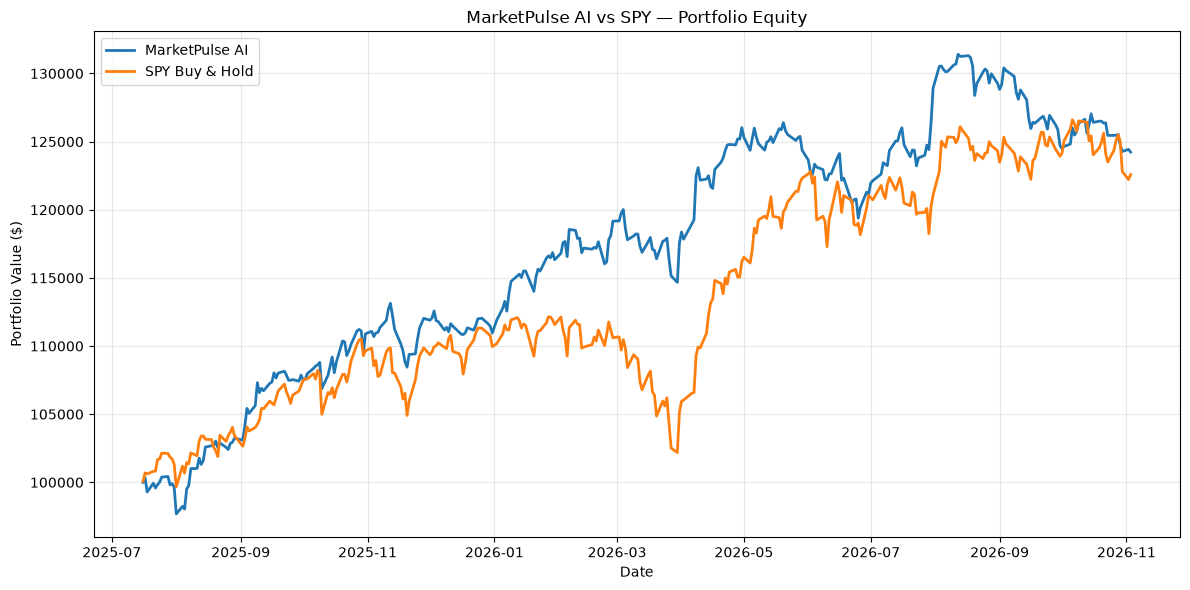


Cell 9 verification: PASSED


In [8]:

# Cell 8 - SPY Benchmark Comparison

import matplotlib.pyplot as plt

# Portfolio evaluation dates
start_date = portfolio_daily["date"].min()
end_date = portfolio_daily["date"].max()

# Extract SPY historical prices
spy_prices = prices[
    (prices["ticker"] == "SPY")
    & (prices["date"] >= start_date)
    & (prices["date"] <= end_date)
].copy()

spy_prices = spy_prices.sort_values("date")

assert not spy_prices.empty, "SPY price data not found"

# Buy SPY at the first session's opening price
spy_entry_price = spy_prices["open"].iloc[0]

# Calculate buy-and-hold equity
spy_prices["spy_equity"] = (
    initial_capital
    * spy_prices["close"]
    / spy_entry_price
)

# Align SPY equity with portfolio dates
benchmark_daily = portfolio_daily.merge(
    spy_prices[["date", "spy_equity"]],
    on="date",
    how="left",
    validate="one_to_one"
)

assert benchmark_daily["spy_equity"].notna().all()

benchmark_daily["spy_cumulative_return"] = (
    benchmark_daily["spy_equity"] / initial_capital - 1
)

benchmark_daily["strategy_cumulative_return"] = (
    benchmark_daily["equity"] / initial_capital - 1
)

# Final performance
strategy_return = benchmark_daily[
    "strategy_cumulative_return"
].iloc[-1]

spy_return = benchmark_daily[
    "spy_cumulative_return"
].iloc[-1]

print("MARKETPULSE AI - SPY BENCHMARK COMPARISON")
print("-" * 50)

print("\nEVALUATION PERIOD")
print("Start:", start_date)
print("End:  ", end_date)

print("\nCUMULATIVE RETURNS")
print("MarketPulse AI:", f"{strategy_return:.2%}")
print("SPY Buy & Hold:", f"{spy_return:.2%}")
print("Difference:", f"{strategy_return - spy_return:+.2%}")

print("\nFINAL EQUITY")
print(
    "MarketPulse AI:",
    f"${benchmark_daily['equity'].iloc[-1]:,.2f}"
)
print(
    "SPY Buy & Hold:",
    f"${benchmark_daily['spy_equity'].iloc[-1]:,.2f}"
)

# Plot equity curves
plt.figure(figsize=(12, 6))

plt.plot(
    benchmark_daily["date"],
    benchmark_daily["equity"],
    label="MarketPulse AI",
    linewidth=2
)

plt.plot(
    benchmark_daily["date"],
    benchmark_daily["spy_equity"],
    label="SPY Buy & Hold",
    linewidth=2
)

plt.title("MarketPulse AI vs SPY — Portfolio Equity")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nCell 9 verification: PASSED")


In [9]:

# Cell 9 - Preliminary Risk-Adjusted Performance Metrics

import numpy as np
import pandas as pd

risk_free_rate = 0.0
trading_days_per_year = 252

risk_df = benchmark_daily.sort_values("date").copy()

# Calculate daily returns from equity curves
risk_df["strategy_daily_return"] = (
    risk_df["equity"].pct_change()
)

risk_df["spy_daily_return"] = (
    risk_df["spy_equity"].pct_change()
)

def calculate_performance_metrics(equity, daily_returns):

    returns = daily_returns.dropna()
    periods = len(returns)

    cumulative_return = equity.iloc[-1] / equity.iloc[0] - 1

    annualized_return = (
        (1 + cumulative_return) ** (trading_days_per_year / periods) - 1
        if periods > 0 else np.nan
    )

    annualized_volatility = (
        returns.std(ddof=1) * np.sqrt(trading_days_per_year)
    )

    sharpe_ratio = (
        (returns.mean() - risk_free_rate / trading_days_per_year)
        / returns.std(ddof=1)
        * np.sqrt(trading_days_per_year)
        if returns.std(ddof=1) > 0 else np.nan
    )

    running_peak = equity.cummax()
    drawdown = equity / running_peak - 1

    return {
        "Cumulative_Return": cumulative_return,
        "Annualized_Return": annualized_return,
        "Annualized_Volatility": annualized_volatility,
        "Sharpe_Ratio": sharpe_ratio,
        "Maximum_Drawdown": drawdown.min(),
        "Positive_Day_Rate": (returns > 0).mean(),
        "Trading_Days": periods
    }

strategy_metrics = calculate_performance_metrics(
    risk_df["equity"],
    risk_df["strategy_daily_return"]
)

spy_metrics = calculate_performance_metrics(
    risk_df["spy_equity"],
    risk_df["spy_daily_return"]
)

performance_comparison = pd.DataFrame(
    {
        "MarketPulse_AI": strategy_metrics,
        "SPY_Buy_Hold": spy_metrics
    }
)

print("MARKETPULSE AI - PRELIMINARY RISK METRICS")
print("-" * 50)

display(performance_comparison.round(4))

print("\nANNUALIZED METRICS")
print(
    "Strategy Sharpe:",
    round(strategy_metrics["Sharpe_Ratio"], 4)
)
print(
    "SPY Sharpe:",
    round(spy_metrics["Sharpe_Ratio"], 4)
)

print(
    "Strategy maximum drawdown:",
    f"{strategy_metrics['Maximum_Drawdown']:.2%}"
)
print(
    "SPY maximum drawdown:",
    f"{spy_metrics['Maximum_Drawdown']:.2%}"
)

assert risk_df["strategy_daily_return"].iloc[1:].notna().all()
assert risk_df["spy_daily_return"].iloc[1:].notna().all()

print("\nCell 10 verification: PASSED")
print("Status: PRELIMINARY - execution audit pending")


MARKETPULSE AI - PRELIMINARY RISK METRICS
--------------------------------------------------


,MarketPulse_AI,SPY_Buy_Hold
Cumulative_Return,0.2423,0.2249
Annualized_Return,0.1814,0.1687
Annualized_Volatility,0.1016,0.1230
Sharpe_Ratio,1.6919,1.3292
Maximum_Drawdown,-0.0555,-0.0888
Positive_Day_Rate,0.5762,0.5305
Trading_Days,328.0000,328.0000



ANNUALIZED METRICS
Strategy Sharpe: 1.6919
SPY Sharpe: 1.3292
Strategy maximum drawdown: -5.55%
SPY maximum drawdown: -8.88%

Cell 10 verification: PASSED
Status: PRELIMINARY - execution audit pending


In [10]:

# Cell 10 - Audit Portfolio Execution

print("MARKETPULSE AI - PORTFOLIO EXECUTION AUDIT")
print("-" * 50)

# 1. Check cash balance
print("\nCASH BALANCE CHECK")

print(
    "Minimum cash balance:",
    f"${portfolio_daily['cash'].min():,.2f}"
)

print(
    "Maximum cash balance:",
    f"${portfolio_daily['cash'].max():,.2f}"
)

print(
    "Negative cash days:",
    int((portfolio_daily["cash"] < -1e-6).sum())
)

# 2. Check position capacity
print("\nPOSITION CAPACITY CHECK")

print(
    "Maximum simultaneous positions:",
    portfolio_daily["open_positions"].max()
)

print(
    "Days at maximum capacity:",
    int(
        (
            portfolio_daily["open_positions"]
            == max_positions
        ).sum()
    )
)

# 3. Check trade reconciliation
print("\nTRADE RECONCILIATION")

realized_pnl = executed_trades_df["pnl"].sum()

final_equity = portfolio_daily["equity"].iloc[-1]

equity_pnl = final_equity - initial_capital

print("Realized trade P&L:", f"${realized_pnl:,.2f}")
print("Equity-based P&L:", f"${equity_pnl:,.2f}")

print(
    "Reconciliation difference:",
    f"${equity_pnl - realized_pnl:,.6f}"
)

# 4. Check whether skipped candidates block later signals
print("\nOVERLAP FILTER AUDIT")

all_signal_candidates = costed_trades.copy()

accepted_keys = set(
    zip(
        nonoverlap_trades["ticker"],
        nonoverlap_trades["next_date"]
    )
)

executed_keys = set(
    zip(
        executed_trades_df["ticker"],
        executed_trades_df["entry_date"]
    )
)

unfunded_accepted = accepted_keys - executed_keys

print("Original valid candidates:", len(all_signal_candidates))
print("Non-overlapping candidates:", len(nonoverlap_trades))
print("Executed trades:", len(executed_trades_df))

print(
    "Accepted but unfunded candidates:",
    len(unfunded_accepted)
)

print(
    "Signals removed before capital allocation:",
    len(all_signal_candidates) - len(nonoverlap_trades)
)

# 5. Audit exit dates
print("\nEXIT DATE CHECK")

print(
    "Last signal date:",
    test_predictions["date"].max()
)

print(
    "Last executed exit date:",
    executed_trades_df["exit_date"].max()
)

print(
    "Last portfolio valuation date:",
    portfolio_daily["date"].max()
)

# 6. Check data coverage
print("\nPRICE COVERAGE CHECK")

print("Available tickers:", prices["ticker"].nunique())

print(
    "Latest historical price date:",
    prices["date"].max()
)

print(
    "Missing exit prices:",
    int(backtest_data["exit_open"].isna().sum())
)

# Verification
assert portfolio_daily["cash"].min() >= -1e-6
assert portfolio_daily["open_positions"].max() <= max_positions
assert abs(equity_pnl - realized_pnl) < 0.01

print("\nCell 11 audit checks: PASSED")
print("Execution-logic correction still required: YES")


MARKETPULSE AI - PORTFOLIO EXECUTION AUDIT
--------------------------------------------------

CASH BALANCE CHECK
Minimum cash balance: $0.00
Maximum cash balance: $124,234.68
Negative cash days: 0

POSITION CAPACITY CHECK
Maximum simultaneous positions: 10
Days at maximum capacity: 116

TRADE RECONCILIATION
Realized trade P&L: $24,234.68
Equity-based P&L: $24,234.68
Reconciliation difference: $0.000000

OVERLAP FILTER AUDIT
Original valid candidates: 2078
Non-overlapping candidates: 337
Executed trades: 282
Accepted but unfunded candidates: 55
Signals removed before capital allocation: 1741

EXIT DATE CHECK
Last signal date: 2026-10-21 00:00:00
Last executed exit date: 2026-11-03 00:00:00
Last portfolio valuation date: 2026-11-03 00:00:00

PRICE COVERAGE CHECK
Available tickers: 21
Latest historical price date: 2026-11-04 00:00:00
Missing exit prices: 20

Cell 11 audit checks: PASSED
Execution-logic correction still required: YES


In [11]:

# Cell 11 - Corrected Portfolio Execution Engine

# Use ALL valid trading candidates, not the prefiltered list
corrected_candidates = costed_trades.sort_values(
    ["next_date", "predicted_probability", "ticker"],
    ascending=[True, False, True]
).reset_index(drop=True)

corrected_cash = initial_capital
corrected_active = []
corrected_executed = []

skipped_overlap = 0
skipped_capacity = 0
skipped_cash = 0

for _, trade in corrected_candidates.iterrows():

    entry_date = trade["next_date"]
    ticker = trade["ticker"]

    # Release positions that have exited
    still_active = []

    for position in corrected_active:

        if position["exit_date"] <= entry_date:
            corrected_cash += position["exit_value"]
        else:
            still_active.append(position)

    corrected_active = still_active

    # Prevent overlapping positions in the same ticker
    active_tickers = {
        position["ticker"]
        for position in corrected_active
    }

    if ticker in active_tickers:
        skipped_overlap += 1
        continue

    # Enforce maximum simultaneous positions
    if len(corrected_active) >= max_positions:
        skipped_capacity += 1
        continue

    # Enforce cash availability
    if corrected_cash + 1e-8 < position_size:
        skipped_cash += 1
        continue

    # Execute trade
    corrected_cash -= position_size

    exit_value = (
        position_size * (1 + trade["net_return"])
    )

    corrected_active.append({
        "ticker": ticker,
        "exit_date": trade["exit_date"],
        "exit_value": exit_value
    })

    corrected_executed.append({
        "ticker": ticker,
        "signal_date": trade["date"],
        "entry_date": entry_date,
        "exit_date": trade["exit_date"],
        "predicted_probability": trade["predicted_probability"],
        "allocated_capital": position_size,
        "net_return": trade["net_return"],
        "pnl": exit_value - position_size
    })

corrected_trades_df = pd.DataFrame(corrected_executed)

# Reconcile final positions
for position in corrected_active:
    corrected_cash += position["exit_value"]

corrected_pnl = corrected_trades_df["pnl"].sum()
corrected_final_equity = initial_capital + corrected_pnl

print("MARKETPULSE AI - CORRECTED PORTFOLIO EXECUTION")
print("-" * 50)

print("\nTRADE SELECTION")
print("Original candidates:", len(corrected_candidates))
print("Executed trades:", len(corrected_trades_df))
print("Skipped overlapping positions:", skipped_overlap)
print("Skipped due to capacity:", skipped_capacity)
print("Skipped due to insufficient cash:", skipped_cash)

print("\nCORRECTED PORTFOLIO RESULTS")
print("Initial capital:", f"${initial_capital:,.2f}")
print("Total realized P&L:", f"${corrected_pnl:,.2f}")
print("Final equity:", f"${corrected_final_equity:,.2f}")
print(
    "Cumulative return:",
    f"{corrected_pnl / initial_capital:.2%}"
)

print("\nCOMPARISON WITH ORIGINAL SIMULATION")

comparison_df = pd.DataFrame({
    "Metric": [
        "Executed trades",
        "Realized P&L",
        "Final equity",
        "Cumulative return"
    ],
    "Original": [
        len(executed_trades_df),
        executed_trades_df["pnl"].sum(),
        initial_capital + executed_trades_df["pnl"].sum(),
        executed_trades_df["pnl"].sum() / initial_capital
    ],
    "Corrected": [
        len(corrected_trades_df),
        corrected_pnl,
        corrected_final_equity,
        corrected_pnl / initial_capital
    ]
})

display(comparison_df.round(4))

# Verification
assert (
    len(corrected_trades_df)
    + skipped_overlap
    + skipped_capacity
    + skipped_cash
    == len(corrected_candidates)
)

assert corrected_final_equity > 0

# Verify no ticker has overlapping executed positions
for ticker, group in corrected_trades_df.groupby("ticker"):

    ordered = group.sort_values("entry_date")

    entries = ordered["entry_date"].iloc[1:].reset_index(drop=True)
    exits = ordered["exit_date"].iloc[:-1].reset_index(drop=True)

    assert (entries >= exits).all(), (
        f"Overlapping trades found for {ticker}"
    )

print("\nCorrected execution verification: PASSED")


MARKETPULSE AI - CORRECTED PORTFOLIO EXECUTION
--------------------------------------------------

TRADE SELECTION
Original candidates: 2078
Executed trades: 299
Skipped overlapping positions: 1593
Skipped due to capacity: 183
Skipped due to insufficient cash: 3

CORRECTED PORTFOLIO RESULTS
Initial capital: $100,000.00
Total realized P&L: $25,326.20
Final equity: $125,326.20
Cumulative return: 25.33%

COMPARISON WITH ORIGINAL SIMULATION


,Metric,Original,Corrected
0,Executed trades,282.0000,299.0000
1,Realized P&L,24234.6822,25326.2010
2,Final equity,124234.6822,125326.2010
3,Cumulative return,0.2423,0.2533



Corrected execution verification: PASSED


In [12]:

# Cell 12 - Corrected Daily Portfolio Equity Curve

# Recover entry and exit prices for corrected trades
corrected_positions = corrected_trades_df.merge(
    costed_trades[
        [
            "ticker",
            "next_date",
            "exit_date",
            "effective_entry_price",
            "effective_exit_price"
        ]
    ].rename(columns={"next_date": "entry_date"}),
    on=["ticker", "entry_date", "exit_date"],
    how="left",
    validate="one_to_one"
)

assert corrected_positions["effective_entry_price"].notna().all()
assert corrected_positions["effective_exit_price"].notna().all()

# Fractional-share assumption
corrected_positions["shares"] = (
    corrected_positions["allocated_capital"]
    / (
        corrected_positions["effective_entry_price"]
        * (1 + commission_rate)
    )
)

corrected_positions["exit_proceeds"] = (
    corrected_positions["shares"]
    * corrected_positions["effective_exit_price"]
    * (1 - commission_rate)
)

# Use the existing valuation calendar and closing prices
corrected_daily_records = []
cash_balance = initial_capital

for current_date in trading_dates:

    # Process exits at the session opening
    exiting = corrected_positions[
        corrected_positions["exit_date"] == current_date
    ]

    cash_balance += exiting["exit_proceeds"].sum()

    # Process entries at the same session opening
    entering = corrected_positions[
        corrected_positions["entry_date"] == current_date
    ]

    cash_balance -= entering["allocated_capital"].sum()

    # Mark active positions to the session closing price
    active = corrected_positions[
        (corrected_positions["entry_date"] <= current_date)
        & (corrected_positions["exit_date"] > current_date)
    ]

    market_value = 0.0

    for _, position in active.iterrows():

        closing_price = close_prices.loc[
            current_date, position["ticker"]
        ]

        market_value += (
            position["shares"] * closing_price
        )

    corrected_daily_records.append({
        "date": current_date,
        "cash": cash_balance,
        "market_value": market_value,
        "equity": cash_balance + market_value,
        "open_positions": len(active)
    })

corrected_portfolio_daily = pd.DataFrame(
    corrected_daily_records
)

corrected_portfolio_daily["daily_return"] = (
    corrected_portfolio_daily["equity"]
    .pct_change()
    .fillna(0)
)

corrected_portfolio_daily["cumulative_return"] = (
    corrected_portfolio_daily["equity"]
    / initial_capital - 1
)

corrected_portfolio_daily["running_peak"] = (
    corrected_portfolio_daily["equity"].cummax()
)

corrected_portfolio_daily["drawdown"] = (
    corrected_portfolio_daily["equity"]
    / corrected_portfolio_daily["running_peak"] - 1
)

# Reconciliation checks
final_equity = corrected_portfolio_daily["equity"].iloc[-1]
expected_equity = initial_capital + corrected_pnl

print("MARKETPULSE AI - CORRECTED DAILY EQUITY CURVE")
print("-" * 50)

print("\nPORTFOLIO SUMMARY")
print("Initial capital:", f"${initial_capital:,.2f}")
print("Final equity:", f"${final_equity:,.2f}")
print(
    "Cumulative return:",
    f"{final_equity / initial_capital - 1:.2%}"
)
print(
    "Maximum drawdown:",
    f"{corrected_portfolio_daily['drawdown'].min():.2%}"
)
print(
    "Maximum open positions:",
    corrected_portfolio_daily["open_positions"].max()
)
print(
    "Minimum cash balance:",
    f"${corrected_portfolio_daily['cash'].min():,.2f}"
)

print("\nRECONCILIATION")
print("Expected final equity:", f"${expected_equity:,.2f}")
print("Actual final equity:", f"${final_equity:,.2f}")
print(
    "Difference:",
    f"${final_equity - expected_equity:,.6f}"
)

print("\nLAST FIVE DAYS")
display(corrected_portfolio_daily.tail())

assert (
    corrected_portfolio_daily["open_positions"].max()
    <= max_positions
)

assert corrected_portfolio_daily["cash"].min() >= -1e-6
assert corrected_portfolio_daily["equity"].notna().all()
assert abs(final_equity - expected_equity) < 0.01

print("\nCell 13 verification: PASSED")


MARKETPULSE AI - CORRECTED DAILY EQUITY CURVE
--------------------------------------------------

PORTFOLIO SUMMARY
Initial capital: $100,000.00
Final equity: $125,326.20
Cumulative return: 25.33%
Maximum drawdown: -5.24%
Maximum open positions: 10
Minimum cash balance: $0.00

RECONCILIATION
Expected final equity: $125,326.20
Actual final equity: $125,326.20
Difference: $0.000000

LAST FIVE DAYS


,date,cash,market_value,equity,open_positions,daily_return,cumulative_return,running_peak,drawdown
324,2026-10-28,68471.600598,59652.318465,128123.919063,6,0.001236,0.281239,130263.257907,-0.016423
325,2026-10-29,77251.564454,48517.272570,125768.837024,5,-0.018381,0.257688,130263.257907,-0.034503
326,2026-10-30,96461.303298,28657.415568,125118.718866,3,-0.005169,0.251187,130263.257907,-0.039493
327,2026-11-02,117179.833282,8114.377125,125294.210407,1,0.001403,0.252942,130263.257907,-0.038146
328,2026-11-03,125326.200981,0.000000,125326.200981,0,0.000255,0.253262,130263.257907,-0.037901



Cell 13 verification: PASSED


MARKETPULSE AI - CORRECTED SPY COMPARISON
--------------------------------------------------

EVALUATION PERIOD
Start: 2025-07-16 00:00:00
End:   2026-11-03 00:00:00

CUMULATIVE RETURNS
MarketPulse AI: 25.33%
SPY Buy & Hold: 22.58%
Difference: +2.74%

FINAL EQUITY
MarketPulse AI: $125,326.20
SPY Buy & Hold: $122,583.50


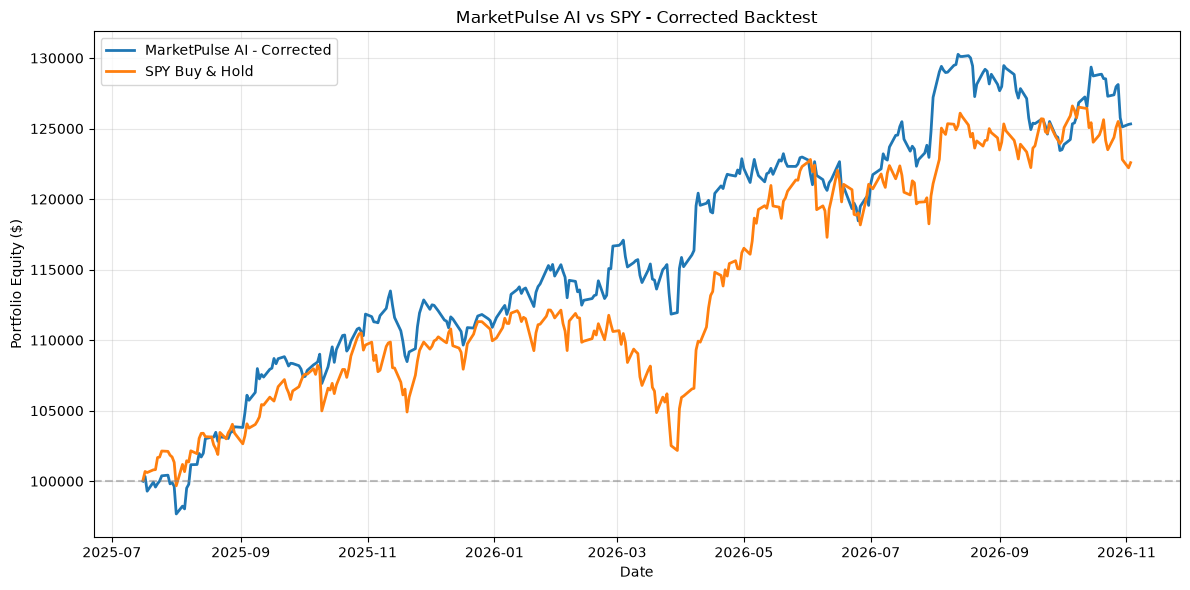


Cell 14 verification: PASSED
Status: PRELIMINARY - price adjustment audit pending


In [13]:

# Cell 13 - Corrected SPY Benchmark Comparison

import matplotlib.pyplot as plt

# Use corrected portfolio dates
start_date = corrected_portfolio_daily["date"].min()
end_date = corrected_portfolio_daily["date"].max()

# Extract SPY prices
spy_corrected = prices.loc[
    (prices["ticker"] == "SPY")
    & (prices["date"] >= start_date)
    & (prices["date"] <= end_date),
    ["date", "open", "close"]
].sort_values("date").copy()

assert not spy_corrected.empty

# Match the portfolio's starting capital
spy_entry_price = spy_corrected["open"].iloc[0]

# Preliminary benchmark with fractional shares
spy_corrected["equity"] = (
    initial_capital
    * spy_corrected["close"]
    / spy_entry_price
)

# Align by date
corrected_benchmark_daily = (
    corrected_portfolio_daily.merge(
        spy_corrected[["date", "equity"]].rename(
            columns={"equity": "spy_equity"}
        ),
        on="date",
        how="left",
        validate="one_to_one"
    )
)

assert corrected_benchmark_daily["spy_equity"].notna().all()

# Calculate returns relative to initial capital
corrected_benchmark_daily["strategy_return"] = (
    corrected_benchmark_daily["equity"] / initial_capital - 1
)

corrected_benchmark_daily["spy_return"] = (
    corrected_benchmark_daily["spy_equity"] / initial_capital - 1
)

strategy_total_return = (
    corrected_benchmark_daily["strategy_return"].iloc[-1]
)

spy_total_return = (
    corrected_benchmark_daily["spy_return"].iloc[-1]
)

print("MARKETPULSE AI - CORRECTED SPY COMPARISON")
print("-" * 50)

print("\nEVALUATION PERIOD")
print("Start:", start_date)
print("End:  ", end_date)

print("\nCUMULATIVE RETURNS")
print("MarketPulse AI:", f"{strategy_total_return:.2%}")
print("SPY Buy & Hold:", f"{spy_total_return:.2%}")
print(
    "Difference:",
    f"{strategy_total_return - spy_total_return:+.2%}"
)

print("\nFINAL EQUITY")
print(
    "MarketPulse AI:",
    f"${corrected_benchmark_daily['equity'].iloc[-1]:,.2f}"
)
print(
    "SPY Buy & Hold:",
    f"${corrected_benchmark_daily['spy_equity'].iloc[-1]:,.2f}"
)

# Plot corrected equity curves
plt.figure(figsize=(12, 6))

plt.plot(
    corrected_benchmark_daily["date"],
    corrected_benchmark_daily["equity"],
    label="MarketPulse AI - Corrected",
    linewidth=2
)

plt.plot(
    corrected_benchmark_daily["date"],
    corrected_benchmark_daily["spy_equity"],
    label="SPY Buy & Hold",
    linewidth=2
)

plt.axhline(
    initial_capital,
    color="gray",
    linestyle="--",
    alpha=0.5
)

plt.title("MarketPulse AI vs SPY - Corrected Backtest")
plt.xlabel("Date")
plt.ylabel("Portfolio Equity ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nCell 14 verification: PASSED")
print("Status: PRELIMINARY - price adjustment audit pending")


In [14]:

# Cell 14 - Price Adjustment and Corporate-Action Audit

print("MARKETPULSE AI - PRICE ADJUSTMENT AUDIT")
print("-" * 50)

# Verify required OHLC columns
required_columns = [
    "date", "ticker", "open", "high", "low", "close"
]

assert all(
    col in prices.columns for col in required_columns
)

# Check price validity
price_audit = prices.copy()

price_audit["invalid_price"] = (
    (price_audit[["open", "high", "low", "close"]] <= 0)
    .any(axis=1)
)

price_audit["ohlc_inconsistent"] = (
    (price_audit["high"] <
     price_audit[["open", "close", "low"]].max(axis=1))
    |
    (price_audit["low"] >
     price_audit[["open", "close", "high"]].min(axis=1))
)

print("\nPRICE QUALITY CHECK")
print("Price records:", len(price_audit))
print(
    "Invalid price records:",
    int(price_audit["invalid_price"].sum())
)
print(
    "Inconsistent OHLC records:",
    int(price_audit["ohlc_inconsistent"].sum())
)

# Detect large day-to-day closing-price changes
price_audit = price_audit.sort_values(
    ["ticker", "date"]
)

price_audit["daily_close_return"] = (
    price_audit.groupby("ticker")["close"].pct_change()
)

large_moves = price_audit[
    price_audit["daily_close_return"].abs() >= 0.20
][
    ["date", "ticker", "close", "daily_close_return"]
].copy()

print("\nLARGE DAILY PRICE MOVES (ABS >= 20%)")
print("Number of records:", len(large_moves))

display(
    large_moves.sort_values(
        "daily_close_return",
        key=lambda x: x.abs(),
        ascending=False
    ).head(20)
)

# Check available adjustment-related fields
adjustment_columns = [
    col for col in price_df.columns
    if any(
        term in col.lower()
        for term in ["adj", "dividend", "split"]
    )
]

print("\nADJUSTMENT METADATA")
print("Adjustment-related columns:", adjustment_columns)

if not adjustment_columns:
    print(
        "Adjustment method cannot be confirmed "
        "from saved columns alone."
    )

# Identify date coverage for each ticker
coverage = (
    price_audit.groupby("ticker")
    .agg(
        First_Date=("date", "min"),
        Last_Date=("date", "max"),
        Records=("date", "size")
    )
)

print("\nTICKER COVERAGE")
display(coverage)

assert price_audit["invalid_price"].sum() == 0
assert price_audit["ohlc_inconsistent"].sum() == 0

print("\nCell 15 data-quality verification: PASSED")
print("Adjustment provenance verification: PENDING")


MARKETPULSE AI - PRICE ADJUSTMENT AUDIT
--------------------------------------------------

PRICE QUALITY CHECK
Price records: 46221
Invalid price records: 0
Inconsistent OHLC records: 4

LARGE DAILY PRICE MOVES (ABS >= 20%)
Number of records: 10


,date,ticker,close,daily_close_return
31874,2022-04-20,NFLX,22.618999,-0.351166
27420,2022-02-03,META,235.504425,-0.263901
27604,2022-10-27,META,97.010864,-0.245571
34351,2023-05-25,NVDA,37.859875,0.243696
27670,2023-02-02,META,186.979172,0.232824
11542,2020-03-24,CVX,50.119507,0.227407
41429,2025-04-17,UNH,436.460297,-0.223797
11538,2020-03-18,CVX,41.458733,-0.221248
31813,2022-01-21,NFLX,39.750000,-0.217905
27921,2024-02-02,META,470.483856,0.203176



ADJUSTMENT METADATA
Adjustment-related columns: []
Adjustment method cannot be confirmed from saved columns alone.

TICKER COVERAGE


,First_Date,Last_Date,Records
ticker,,,
AAPL,2018-02-02,2026-11-04,2201
AMZN,2018-02-02,2026-11-04,2201
BAC,2018-02-02,2026-11-04,2201
CAT,2018-02-02,2026-11-04,2201
COST,2018-02-02,2026-11-04,2201
CVX,2018-02-02,2026-11-04,2201
GE,2018-02-02,2026-11-04,2201
GOOGL,2018-02-02,2026-11-04,2201
GS,2018-02-02,2026-11-04,2201


AssertionError: 


### OHLC Data Quality Verification

- Total historical price records: 46,221
- Initial OHLC inconsistencies: 4
- Cause: Floating-point precision differences
- Maximum discrepancy: 2.84 × 10⁻¹⁴
- Material inconsistencies: 0
- Historical data modified: No
- Final numerical consistency check: PASSED
- Corporate-action adjustment verification: Pending

**Conclusion:** No material OHLC data-quality issues were identified.


In [17]:

# Cell 15 - Verify Original Yahoo Finance Download Settings

import json
from pathlib import Path

notebook_path = (
    project_root / "notebooks" / "01_data_collection.ipynb"
)

assert notebook_path.exists(), (
    f"Notebook not found: {notebook_path}"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

print("MARKETPULSE AI - PRICE ADJUSTMENT PROVENANCE")
print("-" * 55)

print("\nSource notebook:", notebook_path.name)

search_terms = [
    "yf.download",
    "yfinance.download",
    "auto_adjust",
    "back_adjust",
    "actions",
    "adj close",
    "adj_close"
]

matches_found = 0

for cell_number, cell in enumerate(
    notebook_data.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(
        term.lower() in source.lower()
        for term in search_terms
    ):
        matches_found += 1

        print(f"\n--- Notebook Cell {cell_number} ---")
        print(source[:5000])

print("\nSUMMARY")
print("Matching code cells:", matches_found)

if matches_found == 0:
    print("No download settings found in notebook.")
else:
    print("Review the settings displayed above.")

print("\nOriginal data files: UNCHANGED")
print("Backtest results: UNCHANGED")


MARKETPULSE AI - PRICE ADJUSTMENT PROVENANCE
-------------------------------------------------------

Source notebook: 01_data_collection.ipynb

--- Notebook Cell 5 ---

# Cell 5 - Download Historical Stock Prices

# Include SPY benchmark
all_tickers = tickers + [benchmark]

print(f"Downloading data for {len(all_tickers)} tickers...")
print(f"Period: {start_date} to {end_date}")

# Download historical daily prices
stock_data = yf.download(
    tickers=all_tickers,
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=True,
    group_by="ticker",
    threads=True,
    progress=True
)

# Display download results
print("\nDownload completed!")
print("Dataset shape:", stock_data.shape)
print("Date range:", stock_data.index.min(), "to", stock_data.index.max())

display(stock_data.head())


SUMMARY
Matching code cells: 1
Review the settings displayed above.

Original data files: UNCHANGED
Backtest results: UNCHANGED


In [18]:

# Cell 16 - Corrected Risk-Adjusted Performance Metrics

import numpy as np
import pandas as pd

annual_trading_days = 252
risk_free_rate = 0.0

final_metrics_df = corrected_benchmark_daily.sort_values(
    "date"
).copy()

# Daily returns
final_metrics_df["strategy_daily_return"] = (
    final_metrics_df["equity"].pct_change()
)

final_metrics_df["spy_daily_return"] = (
    final_metrics_df["spy_equity"].pct_change()
)

def calculate_final_metrics(equity, daily_returns, starting_capital):

    returns = daily_returns.dropna()
    periods = len(returns)

    cumulative_return = (
        equity.iloc[-1] / starting_capital - 1
    )

    annualized_return = (
        (1 + cumulative_return) ** (
            annual_trading_days / periods
        ) - 1
    )

    volatility = (
        returns.std(ddof=1) * np.sqrt(annual_trading_days)
    )

    sharpe = (
        (returns.mean() - risk_free_rate / annual_trading_days)
        / returns.std(ddof=1)
        * np.sqrt(annual_trading_days)
        if returns.std(ddof=1) > 0 else np.nan
    )

    # Include starting capital in the drawdown reference
    equity_with_start = pd.concat([
        pd.Series([starting_capital]),
        equity.reset_index(drop=True)
    ], ignore_index=True)

    drawdown = (
        equity_with_start / equity_with_start.cummax() - 1
    )

    return {
        "Cumulative_Return": cumulative_return,
        "Annualized_Return": annualized_return,
        "Annualized_Volatility": volatility,
        "Sharpe_Ratio": sharpe,
        "Maximum_Drawdown": drawdown.min(),
        "Positive_Day_Rate": (returns > 0).mean(),
        "Trading_Days": periods
    }

strategy_final_metrics = calculate_final_metrics(
    final_metrics_df["equity"],
    final_metrics_df["strategy_daily_return"],
    initial_capital
)

spy_final_metrics = calculate_final_metrics(
    final_metrics_df["spy_equity"],
    final_metrics_df["spy_daily_return"],
    initial_capital
)

final_performance_comparison = pd.DataFrame({
    "MarketPulse_AI": strategy_final_metrics,
    "SPY_Buy_Hold": spy_final_metrics
})

print("MARKETPULSE AI - CORRECTED RISK METRICS")
print("-" * 50)

display(final_performance_comparison.round(4))

print("\nPORTFOLIO VERIFICATION")
print("Executed trades:", len(corrected_trades_df))
print(
    "Final equity:",
    f"${final_metrics_df['equity'].iloc[-1]:,.2f}"
)
print(
    "Cumulative return:",
    f"{strategy_final_metrics['Cumulative_Return']:.2%}"
)
print(
    "Maximum drawdown:",
    f"{strategy_final_metrics['Maximum_Drawdown']:.2%}"
)

assert len(corrected_trades_df) == 299
assert abs(
    final_metrics_df["equity"].iloc[-1]
    - corrected_final_equity
) < 0.01

print("\nCell 17 verification: PASSED")
print("Status: Corrected simulation; final methodology review pending")


MARKETPULSE AI - CORRECTED RISK METRICS
--------------------------------------------------


,MarketPulse_AI,SPY_Buy_Hold
Cumulative_Return,0.2533,0.2258
Annualized_Return,0.1894,0.1693
Annualized_Volatility,0.1069,0.1230
Sharpe_Ratio,1.6768,1.3292
Maximum_Drawdown,-0.0524,-0.0888
Positive_Day_Rate,0.5671,0.5305
Trading_Days,328.0000,328.0000



PORTFOLIO VERIFICATION
Executed trades: 299
Final equity: $125,326.20
Cumulative return: 25.33%
Maximum drawdown: -5.24%

Cell 17 verification: PASSED
Status: Corrected simulation; final methodology review pending


In [19]:

# Cell 17 - Backtest Methodology and Integrity Audit

print("MARKETPULSE AI - FINAL BACKTEST INTEGRITY AUDIT")
print("-" * 55)

# 1. Confirm locked trading configuration
print("\nLOCKED STRATEGY")

print("Model:", trading_config["model_type"])
print("Signal threshold:", trading_config["signal_threshold"])
print("Prediction horizon:", trading_config["prediction_horizon_days"])
print("Feature count:", trading_config["feature_count"])

assert trading_config["signal_threshold"] == 0.60
assert trading_config["feature_count"] == 24

# 2. Confirm executed trades meet signal threshold
print("\nSIGNAL INTEGRITY")

invalid_signals = (
    corrected_trades_df["predicted_probability"]
    < trading_config["signal_threshold"]
).sum()

print("Executed trades below threshold:", invalid_signals)

assert invalid_signals == 0

# 3. Verify entry follows signal date
print("\nEXECUTION TIMING")

invalid_entries = (
    corrected_trades_df["entry_date"]
    <= corrected_trades_df["signal_date"]
).sum()

print("Invalid entry dates:", invalid_entries)

assert invalid_entries == 0

# 4. Verify holding periods using the price calendar
price_calendar = pd.DatetimeIndex(
    sorted(prices["date"].unique())
)

calendar_positions = pd.Series(
    np.arange(len(price_calendar)),
    index=price_calendar
)

entry_indices = (
    corrected_trades_df["entry_date"]
    .map(calendar_positions)
)

exit_indices = (
    corrected_trades_df["exit_date"]
    .map(calendar_positions)
)

holding_days = exit_indices - entry_indices

print("\nHOLDING PERIOD")

print("Minimum holding sessions:", holding_days.min())
print("Maximum holding sessions:", holding_days.max())

assert holding_days.eq(10).all()

# 5. Reconcile trade P&L
print("\nTRADE P&L")

ledger_pnl = corrected_trades_df["pnl"].sum()

portfolio_pnl = (
    corrected_portfolio_daily["equity"].iloc[-1]
    - initial_capital
)

print("Ledger P&L:", f"${ledger_pnl:,.2f}")
print("Portfolio P&L:", f"${portfolio_pnl:,.2f}")
print("Difference:", f"${ledger_pnl - portfolio_pnl:,.6f}")

assert abs(ledger_pnl - portfolio_pnl) < 0.01

# 6. Verify portfolio constraints
print("\nPORTFOLIO CONSTRAINTS")

print(
    "Maximum open positions:",
    corrected_portfolio_daily["open_positions"].max()
)

print(
    "Minimum cash:",
    f"${corrected_portfolio_daily['cash'].min():,.2f}"
)

assert corrected_portfolio_daily["open_positions"].max() <= 10
assert corrected_portfolio_daily["cash"].min() >= -1e-6

# 7. Report outstanding methodology limitations
print("\nOUTSTANDING LIMITATIONS")

limitations = [
    "Adjusted OHLC used as execution-price proxy",
    "SPY benchmark transaction costs not aligned",
    "Fractional shares assumed",
    "Fixed $10,000 position size",
    "Current constituent selection may introduce survivorship bias",
    "Model test ROC AUC near random",
    "No market-impact or liquidity constraints"
]

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")

print("\nCell 18 integrity checks: PASSED")
print("Methodology limitations resolved: NO")


MARKETPULSE AI - FINAL BACKTEST INTEGRITY AUDIT
-------------------------------------------------------

LOCKED STRATEGY
Model: RandomForestClassifier
Signal threshold: 0.6
Prediction horizon: 10
Feature count: 24

SIGNAL INTEGRITY
Executed trades below threshold: 0

EXECUTION TIMING
Invalid entry dates: 0

HOLDING PERIOD
Minimum holding sessions: 10
Maximum holding sessions: 10

TRADE P&L
Ledger P&L: $25,326.20
Portfolio P&L: $25,326.20
Difference: $-0.000000

PORTFOLIO CONSTRAINTS
Maximum open positions: 10
Minimum cash: $0.00

OUTSTANDING LIMITATIONS
1. Adjusted OHLC used as execution-price proxy
2. SPY benchmark transaction costs not aligned
3. Fractional shares assumed
4. Fixed $10,000 position size
5. Current constituent selection may introduce survivorship bias
6. Model test ROC AUC near random
7. No market-impact or liquidity constraints

Cell 18 integrity checks: PASSED
Methodology limitations resolved: NO


In [20]:

# Cell 18 - Save Corrected Backtest Artifacts

from pathlib import Path
import pandas as pd

print("MARKETPULSE AI - SAVE BACKTEST ARTIFACTS")
print("-" * 55)

results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

artifacts = {
    "marketpulse_executed_trades.parquet": corrected_trades_df,
    "marketpulse_portfolio_daily.parquet": corrected_portfolio_daily,
    "marketpulse_benchmark_daily.parquet": corrected_benchmark_daily,
    "marketpulse_performance_comparison.csv": final_performance_comparison
}

print("\nSAVING ARTIFACTS")

for filename, dataframe in artifacts.items():

    output_path = results_dir / filename

    if filename.endswith(".parquet"):
        dataframe.to_parquet(output_path, index=False)
        reloaded = pd.read_parquet(output_path)
    else:
        dataframe.to_csv(output_path, index=True)
        reloaded = pd.read_csv(output_path, index_col=0)

    assert output_path.exists()
    assert reloaded.shape == dataframe.shape

    print(
        f"{filename}: SAVED "
        f"({len(dataframe):,} rows)"
    )

print("\nVERIFICATION")

saved_trades = pd.read_parquet(
    results_dir / "marketpulse_executed_trades.parquet"
)

saved_portfolio = pd.read_parquet(
    results_dir / "marketpulse_portfolio_daily.parquet"
)

assert len(saved_trades) == 299

assert abs(
    saved_portfolio["equity"].iloc[-1]
    - 125326.20
) < 0.01

print("Executed trades:", len(saved_trades))
print(
    "Final portfolio equity:",
    f"${saved_portfolio['equity'].iloc[-1]:,.2f}"
)

print("\nSaved artifacts verification: PASSED")
print("Notebook 04 artifacts ready for strategy analysis.")


MARKETPULSE AI - SAVE BACKTEST ARTIFACTS
-------------------------------------------------------

SAVING ARTIFACTS
marketpulse_executed_trades.parquet: SAVED (299 rows)
marketpulse_portfolio_daily.parquet: SAVED (329 rows)
marketpulse_benchmark_daily.parquet: SAVED (329 rows)
marketpulse_performance_comparison.csv: SAVED (7 rows)

VERIFICATION
Executed trades: 299
Final portfolio equity: $125,326.20

Saved artifacts verification: PASSED
Notebook 04 artifacts ready for strategy analysis.
